# E3: range-query cost vs selectivity (tempo, all rows)

Question: how does the cost of `range_search` depend on selectivity, and which index is best for F3 (workout mode)?
Data: `E3_range_tempo` rows from `results/timings.csv`, one machine, one code version. 200 ranges per selectivity, 5 replicates.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path("..") if (Path("..") / "results/timings.csv").exists() else Path(".")
df = pd.read_csv(root / "results/timings.csv")
rows = df[df["experiment"] == "E3_range_tempo"].copy()

# Control the comparison: one machine, one version, one complete session.
machine = "oscar-omen"
version = "bc253d0-dirty"
before_version = "9598854-dirty"

def select_run(code_version):
    data = rows[(rows["machine_id"] == machine) & (rows["code_version"] == code_version)]
    if data.empty:
        raise ValueError(f"No E3 measurements for {machine}, {code_version}")
    session = data.groupby("session_id")["timestamp_utc"].max().idxmax()
    data = data[data["session_id"] == session].copy()
    counts = data.groupby(["index_type", "operation_param"])["rep"].nunique()
    assert len(counts) == 42 and counts.min() >= 5, "E3 needs all 42 configurations with 5 replicates."
    assert not data.duplicated(["index_type", "operation_param", "rep"]).any()
    assert set(data["n_keys"]) == {114000} and set(data["n_ops"]) == {200}
    data["us_per_op"] = data["total_ns"] / data["n_ops"] / 1000
    for c in ["comparisons", "nodes_visited"]:
        data[c + "_per_op"] = data[c] / data["n_ops"]
    return data

e3 = select_run(version)
figures = root / "report/figures/e3"
tables = root / "report/tables/e3"
figures.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)
print(machine, version, e3["session_id"].iloc[0], len(e3), "rows")
e3.groupby(["index_type", "operation_param"]).size().unstack()

oscar-omen bc253d0-dirty 030a62ad5097 210 rows


operation_param,0.0001,0.0010,0.0100,0.0500,0.1000,0.2500
index_type,,,,,,
avl_tree,5,5,5,5,5,5
bplus_tree,5,5,5,5,5,5
hash_table,5,5,5,5,5,5
ref_bisect,5,5,5,5,5,5
ref_dict,5,5,5,5,5,5
sorted_list,5,5,5,5,5,5
unsorted_list,5,5,5,5,5,5


## Median and IQR across the 5 replicates (µs per range query)

In [2]:
summary = (
    e3.groupby(["index_type", "operation_param"])["us_per_op"]
    .quantile([0.25, 0.5, 0.75]).unstack()
    .rename(columns={0.25: "q25", 0.5: "median", 0.75: "q75"})
)
summary.to_csv(tables / "E3_timing_summary.csv")
summary["median"].unstack("operation_param").round(3)

operation_param,0.0001,0.0010,0.0100,0.0500,0.1000,0.2500
index_type,,,,,,
avl_tree,10.398,46.937,405.664,1793.073,3480.800,8869.518
bplus_tree,8.191,28.456,287.112,1322.572,2539.509,6182.986
hash_table,8484.050,9916.619,10503.040,10560.875,9081.716,12466.019
ref_bisect,4.280,13.797,73.139,273.345,555.184,1720.702
ref_dict,1786.662,1837.701,1842.668,2304.202,2729.931,4592.804
sorted_list,9.307,35.583,318.018,1574.006,3024.492,7355.931
unsorted_list,3570.275,3454.848,3341.747,3483.500,3852.051,4783.447


## Cost vs selectivity

Line = median over replicates, band = IQR. Both axes are logarithmic. Selectivity is the fraction of **distinct tempo keys** covered, not the fraction of rows returned.

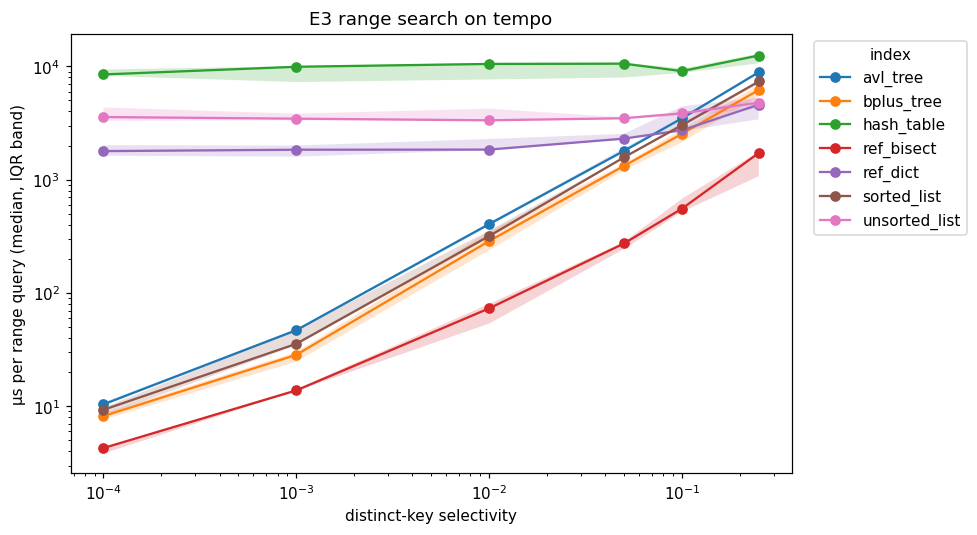

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
for index_type in summary.index.get_level_values(0).unique():
    s = summary.loc[index_type]
    ax.plot(s.index, s["median"], marker="o", label=index_type)
    ax.fill_between(s.index, s["q25"], s["q75"], alpha=0.2)
ax.set(xscale="log", yscale="log", xlabel="distinct-key selectivity",
       ylabel="µs per range query (median, IQR band)", title="E3 range search on tempo")
ax.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
fig.savefig(figures / "E3_range_timing.png", dpi=180, bbox_inches="tight")
plt.show()

## Separating search cost from output cost

A range costs (find the start) + (walk the matching keys) + (copy the matching row IDs). Several rows can share a tempo, so the returned row count differs from the number of distinct keys covered.

In [4]:
workload = e3[["operation_param", "notes"]].drop_duplicates().sort_values("operation_param")
workload["distinct_keys"] = workload["notes"].str.extract(r"distinct_keys=(\d+)", expand=False).astype(int)
workload["keys_in_range"] = workload["notes"].str.extract(r"distinct_keys_per_range=(\d+)", expand=False).astype(int)
workload["avg_rows_returned"] = workload["notes"].str.extract(r"mean_rows_returned=([\d.]+)", expand=False).astype(float)
workload = workload.set_index("operation_param")[["distinct_keys", "keys_in_range", "avg_rows_returned"]]
workload.to_csv(tables / "E3_workloads.csv")
workload

,distinct_keys,keys_in_range,avg_rows_returned
operation_param,,,
0.0001,45653,5,12.515
0.0010,45653,46,118.190
0.0100,45653,457,1139.715
0.0500,45653,2283,5783.200
0.1000,45653,4565,11691.010
0.2500,45653,11413,30754.615


## Counters per query

The unsorted list scans all pairs; the hash table scans all distinct keys and buckets. Ordered indexes should visit the search path and matching keys. References leave their counters blank.

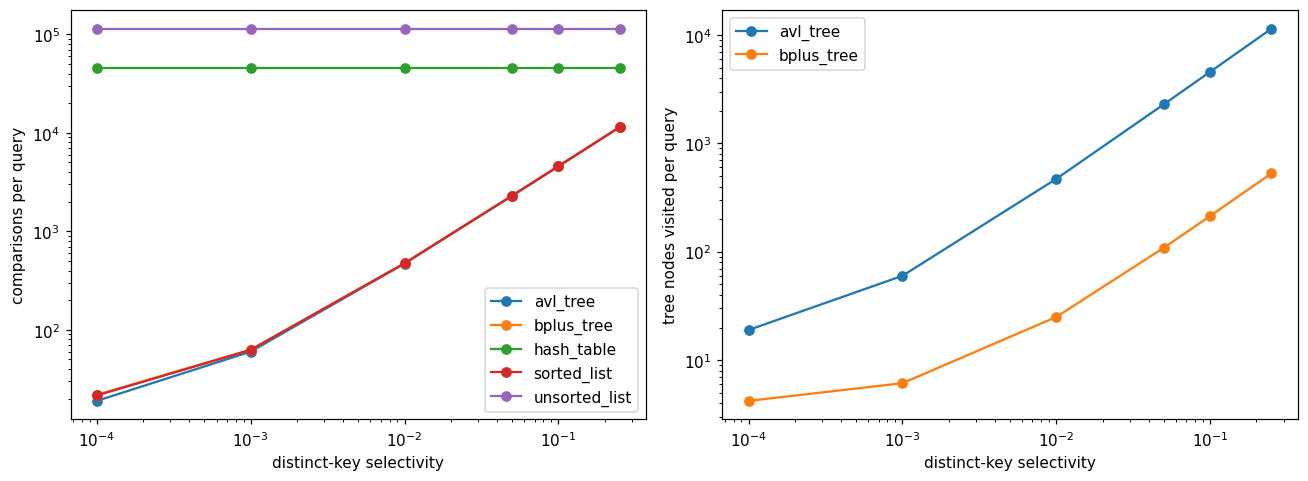

comparisons_per_op  nodes_visited_per_op
index_type    operation_param                                          
avl_tree      0.0001                        18.98                 18.98
              0.0010                        60.02                 60.02
              0.0100                       470.92                470.92
              0.0500                      2296.49               2296.49
              0.1000                      4578.31               4578.31
              0.2500                     11425.98              11425.98
bplus_tree    0.0001                        21.87                  4.21
              0.0010                        62.88                  6.13
              0.0100                       473.88                 25.05
              0.0500                      2299.89                108.96
              0.1000                      4581.84                214.05
              0.2500                     11429.80                529.02
hash_table    0.0001                     45653.00              65536.00
              0.0010                     45653.00              65536.00
              0.0100                     45653.00              65536.00
              0.0500                     45653.00              65536.00
              0.1000                     45653.00              65536.00
              0.2500                     45653.00              65536.00
sorted_list   0.0001                        21.54                  0.00
              0.0010                        62.54                  0.00
              0.0100                       473.54                  0.00
              0.0500                      2299.54                  0.00
              0.1000                      4581.56                  0.00
              0.2500                     11429.58                  0.00
unsorted_list 0.0001                    114000.00                  0.00
              0.0010                    114000.00                  0.00
              0.0100                    114000.00                  0.00
              0.0500                    114000.00                  0.00
              0.1000                    114000.00                  0.00
              0.2500                    114000.00                  0.00

In [5]:
counted = e3[e3["comparisons"].notna()]
counts = counted.groupby(["index_type", "operation_param"])[
    ["comparisons_per_op", "nodes_visited_per_op"]
].median()
counts.to_csv(tables / "E3_counters.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for index_type, g in counts.groupby(level="index_type"):
    s = g.droplevel("index_type")
    axes[0].plot(s.index, s["comparisons_per_op"], marker="o", label=index_type)
    if index_type in ["avl_tree", "bplus_tree"]:
        axes[1].plot(s.index, s["nodes_visited_per_op"], marker="o", label=index_type)
for ax, ylabel in zip(axes, ["comparisons per query", "tree nodes visited per query"]):
    ax.set(xscale="log", yscale="log", xlabel="distinct-key selectivity", ylabel=ylabel)
    ax.legend()
plt.tight_layout()
fig.savefig(figures / "E3_counters.png", dpi=180, bbox_inches="tight")
plt.show()
counts.round(2)

## Best index at each selectivity (crossovers)

The five main indexes are the candidates. The references show implementation constants. The best and runner-up are ranked by median; overlapping IQRs do not establish a clear timing difference.

In [6]:
med = summary["median"].unstack("operation_param")
main = med.drop(index=["ref_dict", "ref_bisect"])
best = pd.DataFrame({
    "best main index": main.idxmin(),
    "µs": main.min(),
    "runner-up": main.apply(lambda c: c.nsmallest(2).index[-1]),
    "ref_bisect µs": med.loc["ref_bisect"],
})
best["IQRs overlap"] = [
    max(summary.loc[(row["best main index"], selectivity), "q25"],
        summary.loc[(row["runner-up"], selectivity), "q25"])
    <= min(summary.loc[(row["best main index"], selectivity), "q75"],
           summary.loc[(row["runner-up"], selectivity), "q75"])
    for selectivity, row in best.iterrows()
]
best.to_csv(tables / "E3_best_indexes.csv")
best.round(3)

,best main index,µs,runner-up,ref_bisect µs,IQRs overlap
operation_param,,,,,
0.0001,bplus_tree,8.191,sorted_list,4.280,True
0.0010,bplus_tree,28.456,sorted_list,13.797,False
0.0100,bplus_tree,287.112,sorted_list,73.139,True
0.0500,bplus_tree,1322.572,sorted_list,273.345,False
0.1000,bplus_tree,2539.509,sorted_list,555.184,False
0.2500,unsorted_list,4783.447,bplus_tree,1720.702,False


## B+ tree before and after the range-search fix

Same computer, order 32, query counts, selectivities and workload notes. The old method traverses every subtree; the fix finds the starting leaf and follows `next` until the upper bound. Before/final timing ratio greater than 1 means the final run was faster.

before: 9598854-dirty final: bc253d0-dirty


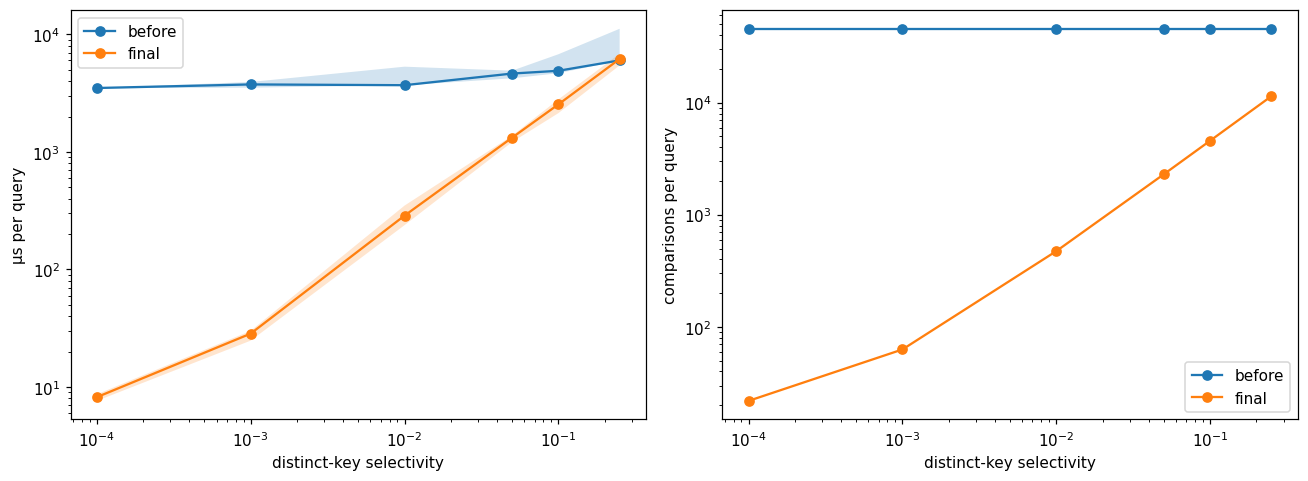

,before µs,final µs,before comparisons,final comparisons,before nodes,final nodes,before/final time
operation_param,,,,,,,
0.0001,3498.708,8.191,45653.0,21.870,2197.0,4.210,427.115
0.0010,3753.706,28.456,45653.0,62.875,2197.0,6.130,131.911
0.0100,3696.974,287.112,45653.0,473.885,2197.0,25.050,12.876
0.0500,4644.550,1322.572,45653.0,2299.885,2197.0,108.965,3.512
0.1000,4903.161,2539.509,45653.0,4581.845,2197.0,214.050,1.931
0.2500,6014.273,6182.986,45653.0,11429.805,2197.0,529.025,0.973


In [7]:
before = select_run(before_version)
b = before[before["index_type"] == "bplus_tree"].copy()
a = e3[e3["index_type"] == "bplus_tree"].copy()
assert set(zip(b["operation_param"], b["notes"])) == set(zip(a["operation_param"], a["notes"]))
b["phase"] = "before"
a["phase"] = "final"
combined = pd.concat([b, a])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, ylabel in zip(axes, ["us_per_op", "comparisons_per_op"],
                             ["µs per query", "comparisons per query"]):
    s = (combined.groupby(["phase", "operation_param"])[metric]
         .quantile([.25, .5, .75]).unstack())
    for phase in ["before", "final"]:
        g = s.loc[phase]
        ax.plot(g.index, g[.5], marker="o", label=phase)
        ax.fill_between(g.index, g[.25], g[.75], alpha=.2)
    ax.set(xscale="log", yscale="log", xlabel="distinct-key selectivity", ylabel=ylabel)
    ax.legend()
plt.tight_layout()
fig.savefig(figures / "E3_Bplus_before_after.png", dpi=180, bbox_inches="tight")
plt.show()

comparison = pd.DataFrame({
    "before µs": b.groupby("operation_param")["us_per_op"].median(),
    "final µs": a.groupby("operation_param")["us_per_op"].median(),
    "before comparisons": b.groupby("operation_param")["comparisons_per_op"].median(),
    "final comparisons": a.groupby("operation_param")["comparisons_per_op"].median(),
    "before nodes": b.groupby("operation_param")["nodes_visited_per_op"].median(),
    "final nodes": a.groupby("operation_param")["nodes_visited_per_op"].median(),
})
comparison["before/final time"] = comparison["before µs"] / comparison["final µs"]
comparison.to_csv(tables / "E3_Bplus_before_after.csv")
print("before:", before_version, "final:", version)
comparison.round(3)

## Observations

- **Selectivity.** B+ has the lowest main-index median from 0.0001 through 0.1. At 0.0001 it costs 8.19 µs per query, compared with 9.31 for the sorted list and 10.40 for AVL. Its IQR overlaps the sorted list at that smallest selectivity, so that small difference is not a clear win.
- **Broad ranges.** At 0.25, the unsorted list has the lowest main-index median: 4783.4 µs versus 6183.0 for B+. The observed winner changes between selectivities 0.1 and 0.25; the experiment does not locate an exact crossover within that interval. The widest ranges return about 30,755 rows on average, making output work substantial.
- **Counters vs theory.** The unsorted list examines all 114,000 pairs per query. The hash table examines all 45,653 distinct tempos. Ordered indexes do less work on narrow ranges, consistent with O(log d + r), where d is distinct keys and r is returned row IDs.
- **B+ fix.** At 0.0001, the median drops from 3498.71 to 8.19 µs, about 427.1× faster in the recorded runs. Comparisons drop from 45,653 to 21.87 per query. At 0.25 there is no median timing improvement, even though comparisons decrease: a broad range still returns many rows. Timing variation also affects this comparison, so the counters are useful evidence of the algorithm change.
- **References.** `ref_bisect` is about 2.2–5.8× faster than the sorted-list implementation. They use the same ordered-search idea; C-backed binary search changes constant factors, while result assembly still costs time.
- **Recommendation for F3.** B+ is a strong choice for selective tempo ranges in these measurements. A plain scan becomes competitive for broad ranges. Build cost and memory from E1 are still needed for a complete recommendation.
- **Measurement scope.** These are five repetitions of one seeded batch on one machine. The recorded versions are `9598854-dirty` and `bc253d0-dirty`; their `-dirty` labels mean the commit hashes alone do not fully identify the measured source.